<a href="https://colab.research.google.com/github/akashuniyal01/E-Commerce-Customer-Intelligence/blob/main/interaction_data_cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# data cleaning interaction.csv

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
from google.colab import files

uploaded = files.upload()

Saving interactions.csv to interactions.csv


In [5]:
df = pd.read_csv("interactions.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 100000
Number of columns: 7


In [7]:
df.head()

,interaction_id,user_id,product_id,session_id,interaction_type,timestamp,dwell_time_ms
0,2ece1c7b-3244-4eeb-8d3e-f1b0cc09f20f,8a49a58e-7e31-4616-8ac8-b1472ed4f5d8,d3701c21-709a-4090-bab2-020261ce8a92,0003375f-8f69-44e1-9429-ec083de18495,view,2025-03-13 08:29:18.000000832,30481
1,bef097f8-4624-406a-9168-fc16f6d9db7a,8a49a58e-7e31-4616-8ac8-b1472ed4f5d8,d3701c21-709a-4090-bab2-020261ce8a92,0003375f-8f69-44e1-9429-ec083de18495,view,2025-03-13 08:29:50.726785665,37889
2,131590fb-aded-4eb2-b04a-158540271950,8a49a58e-7e31-4616-8ac8-b1472ed4f5d8,b1a8533d-7d06-48ae-b1d2-02a39ad1c623,0003375f-8f69-44e1-9429-ec083de18495,view,2025-03-13 08:30:37.244865920,11801
3,dda794be-afc4-4b8c-9a5c-3594d513f261,8a49a58e-7e31-4616-8ac8-b1472ed4f5d8,b1a8533d-7d06-48ae-b1d2-02a39ad1c623,0003375f-8f69-44e1-9429-ec083de18495,view,2025-03-13 08:30:37.244865920,11801
4,b68f3af4-29d1-4d85-884a-5e585d5d0a4a,8a49a58e-7e31-4616-8ac8-b1472ed4f5d8,2ee058a5-f098-4961-a46d-ba699b635b84,0003375f-8f69-44e1-9429-ec083de18495,add_to_wishlist,2025-03-13 08:30:50.152312822,1404


In [8]:
print(df.columns.tolist())

['interaction_id', 'user_id', 'product_id', 'session_id', 'interaction_type', 'timestamp', 'dwell_time_ms']


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 7 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   interaction_id    100000 non-null  object
 1   user_id           100000 non-null  object
 2   product_id        100000 non-null  object
 3   session_id        100000 non-null  object
 4   interaction_type  100000 non-null  object
 5   timestamp         100000 non-null  object
 6   dwell_time_ms     100000 non-null  int64 
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [12]:
## Checking Unique values
print("Unique interaction IDs:", df["interaction_id"].nunique())
print("Unique users:", df["user_id"].nunique())
print("Unique products:", df["product_id"].nunique())
print("Unique sessions:", df["session_id"].nunique())

print("\nInteraction types:")
print(df["interaction_type"].value_counts())

Unique interaction IDs: 100000
Unique users: 6944
Unique products: 967
Unique sessions: 19315

Interaction types:
interaction_type
view                    50463
click                   19983
add_to_cart             11860
add_to_wishlist         10168
remove_from_wishlist     4795
remove_from_cart         2731
Name: count, dtype: int64


In [13]:
missing_values = df.isnull().sum()

print(missing_values)
print("\nTotal missing values:", missing_values.sum())

interaction_id      0
user_id             0
product_id          0
session_id          0
interaction_type    0
timestamp           0
dwell_time_ms       0
dtype: int64

Total missing values: 0


In [14]:
## checking duplicates records
print("Completely duplicated rows:", df.duplicated().sum())

print(
    "Duplicate interaction IDs:",
    df["interaction_id"].duplicated().sum()
)

Completely duplicated rows: 0
Duplicate interaction IDs: 0


In [15]:
# Checking Invalid or Blank text values
text_columns = [
    "interaction_id",
    "user_id",
    "product_id",
    "session_id",
    "interaction_type"
]

for col in text_columns:
    blank_count = (
        df[col].astype("string").str.strip().eq("").sum()
    )
    print(f"{col}: {blank_count} blank values")

interaction_id: 0 blank values
user_id: 0 blank values
product_id: 0 blank values
session_id: 0 blank values
interaction_type: 0 blank values


In [16]:
#checkkiing the interaction types

print(df["interaction_type"].value_counts(dropna=False))

interaction_type
view                    50463
click                   19983
add_to_cart             11860
add_to_wishlist         10168
remove_from_wishlist     4795
remove_from_cart         2731
Name: count, dtype: int64


In [17]:
#Checking Numerical values

print(df["dwell_time_ms"].describe())

print(
    "Negative dwell times:",
    (df["dwell_time_ms"] < 0).sum()
)

count    100000.000000
mean      17942.900550
std       21556.684456
min         500.000000
25%        4260.000000
50%       11153.000000
75%       23342.250000
max      300000.000000
Name: dwell_time_ms, dtype: float64
Negative dwell times: 0


In [18]:
# convert text into daytime

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

print("Timestamp conversion completed.")

print(
    "Invalid timestamps:",
    df["timestamp"].isna().sum()
)

df[["interaction_id", "timestamp"]].head()

Timestamp conversion completed.
Invalid timestamps: 0


,interaction_id,timestamp
0,2ece1c7b-3244-4eeb-8d3e-f1b0cc09f20f,2025-03-13 08:29:18.000000832
1,bef097f8-4624-406a-9168-fc16f6d9db7a,2025-03-13 08:29:50.726785665
2,131590fb-aded-4eb2-b04a-158540271950,2025-03-13 08:30:37.244865920
3,dda794be-afc4-4b8c-9a5c-3594d513f261,2025-03-13 08:30:37.244865920
4,b68f3af4-29d1-4d85-884a-5e585d5d0a4a,2025-03-13 08:30:50.152312822


In [19]:
# checking the data range

print("Earliest interaction:", df["timestamp"].min())
print("Latest interaction:", df["timestamp"].max())

Earliest interaction: 2023-01-04 00:12:23.000000964
Latest interaction: 2026-05-31 22:38:27.298660882


Cleaning

In [20]:
# creating a clean copy

df_clean = df.copy()

print("Clean copy created.")
print("Original shape:", df.shape)
print("Clean copy shape:", df_clean.shape)

Clean copy created.
Original shape: (100000, 7)
Clean copy shape: (100000, 7)


In [21]:
# standardise tecxt formatting

text_columns = [
    "interaction_id",
    "user_id",
    "product_id",
    "session_id",
    "interaction_type"
]

for col in text_columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()

print("Text formatting standardised.")

Text formatting standardised.


In [22]:
# checking the data again

print("Missing values:")
print(df_clean.isnull().sum())

print("\nDuplicate rows:", df_clean.duplicated().sum())

print(
    "Duplicate interaction IDs:",
    df_clean["interaction_id"].duplicated().sum()
)

print("\nFinal dimensions:", df_clean.shape)

Missing values:
interaction_id      0
user_id             0
product_id          0
session_id          0
interaction_type    0
timestamp           0
dwell_time_ms       0
dtype: int64

Duplicate rows: 0
Duplicate interaction IDs: 0

Final dimensions: (100000, 7)


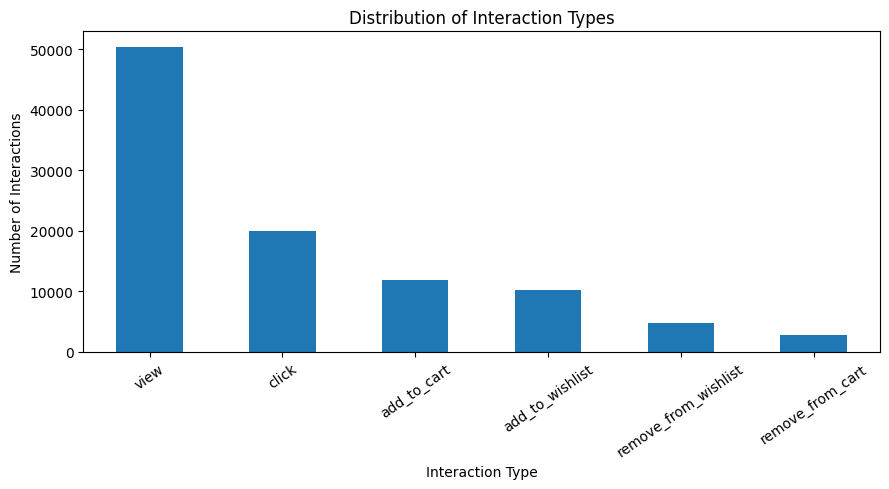

In [23]:
# plot the interaction types

interaction_counts = df_clean["interaction_type"].value_counts()

interaction_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Distribution of Interaction Types")
plt.xlabel("Interaction Type")
plt.ylabel("Number of Interactions")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

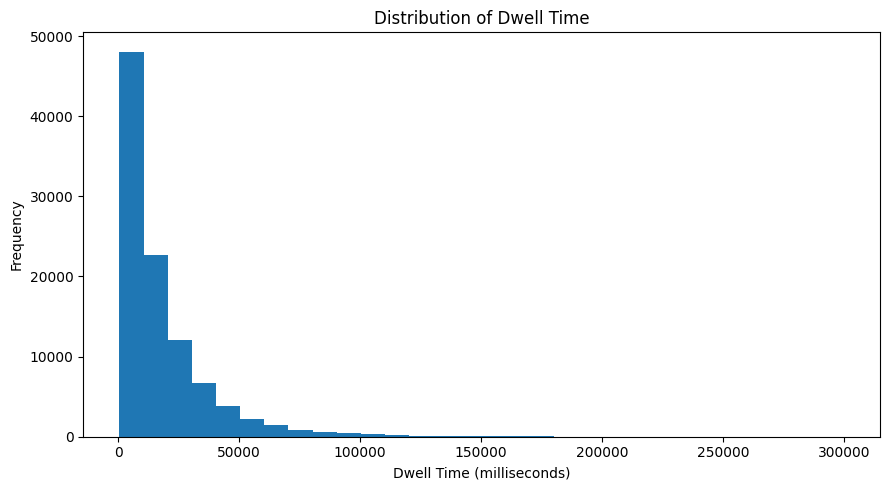

In [24]:
# plotting dwell time

df_clean["dwell_time_ms"].plot(
    kind="hist",
    bins=30,
    figsize=(9, 5)
)

plt.title("Distribution of Dwell Time")
plt.xlabel("Dwell Time (milliseconds)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()#

In [25]:
# Exporting clean files

output_file = "interactions_cleaned.csv"

df_clean.to_csv(output_file, index=False)

print("Cleaned file saved:", output_file)

Cleaned file saved: interactions_cleaned.csv


In [26]:
# Downloading the cleaned file.csv

from google.colab import files

files.download("interactions_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>